# 14 · The Proposed Model

**The question:** Put together the parts that earned their place in Notebooks 10-13, give the result a small, fair tuning, and see how it compares
with every model so far.

| | |
|---|---|
| **Input** | Decisions from Notebooks 10-13; scaled `total_and_byte44` inputs |
| **What we do** | Assemble the proposed network, tune 2 settings on the stopping rows, train 3 seeds, compare with LightGBM, the MLP and the reference model |
| **Output** | The proposed model, its scores, and a fair comparison. Notebook 15 then removes each part to prove what it contributes |

## 1. Setup and the assembled design

In [1]:
import sys
import warnings
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())))
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import confusion_matrix, f1_score, precision_recall_fscore_support

from src.notebook_helpers import (TRAIN_CSV, RAW_SHA256, CLASSES, DATA, MODELS, sha256, save_table, save_figure, save_json,
                                  read_json, setup_style, write_leaderboard)
from src.flow_networks import FlowData, FlowNet, BASE_CONFIG, run_config, train_network, paired_comparison, leaderboard_row, show_code, DEVICE
setup_style()
assert sha256(TRAIN_CSV) == RAW_SHA256['train']

d10, d11, d12, d13 = (read_json(MODELS / f'{n}_rare_class_choice.json' if n == '10' else MODELS / f'{n}_decision.json') for n in ['10', '11', '12', '13'])
DESIGN = dict(BASE_CONFIG, weighting=d10['network_weighting'], scales=d13['scales'], fusion=d13['fusion'], tcn_bilstm=d13['tcn_bilstm'])
steps = pd.DataFrame([
    ('10', 'rare-class weighting', d10['network_weighting'], '-', '-'),
    ('11', 'multi-scale convolution', 'kept' if d11['kept'] else 'not kept', d11['mean gain'], d11['seeds where better']),
    ('12', 'cross-attention fusion', 'kept' if d12['kept'] else 'not kept', d12['mean gain'], d12['seeds where better']),
    ('13', 'TCN-BiLSTM', 'kept' if d13['kept'] else 'not kept', d13['mean gain'], d13['seeds where better']),
], columns=['notebook', 'part', 'decision', 'mean macro F1 gain', 'seeds better'])
display(steps)
print('Assembled design:', {k: DESIGN[k] for k in ['weighting', 'scales', 'fusion', 'tcn_bilstm']}, '| device:', DEVICE)
data = FlowData('total_and_byte44')

,notebook,part,decision,mean macro F1 gain,seeds better
0,10,rare-class weighting,sqrt,-,-
1,11,multi-scale convolution,kept,0.0056,2 of 3
2,12,cross-attention fusion,kept,0.0024,2 of 3
3,13,TCN-BiLSTM,kept,0.0071,2 of 3


Assembled design: {'weighting': 'sqrt', 'scales': [3, 5, 7], 'fusion': 'cross', 'tcn_bilstm': True} | device: cuda


The whole network in one place:

In [2]:
show_code(FlowNet)

```python
class FlowNet(nn.Module):
    """One configurable network. Every experiment in Notebooks 10-15 is a FlowNet with different settings."""

    def __init__(self, len_a, len_b, vocab, scales=(3,), fusion='self', tcn_bilstm=False, channels=64, dropout=0.2):
        super().__init__()
        self.len_a = len_a
        self.branch_a, self.branch_b = ConvBranch(scales, channels), ConvBranch(scales, channels)
        self.position = nn.Parameter(torch.zeros(1, len_a + len_b + len(TEXT), channels))
        self.embeddings = nn.ModuleList([nn.Embedding(vocab[t], channels) for t in TEXT])   # text columns become tokens
        self.fusion = {'self': SelfAttentionFusion, 'cross': CrossAttentionFusion, 'none': ConcatFusion}[fusion](channels)
        self.sequence = TCNBiLSTM(channels) if tcn_bilstm else None
        self.head = nn.Sequential(nn.Linear(channels, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, len(CLASSES)))

    def forward(self, numbers, codes, return_attention=False):
        a = self.branch_a(numbers[:, :self.len_a])
        b = self.branch_b(numbers[:, self.len_a:])
        text_tokens = torch.stack([emb(codes[:, i]) for i, emb in enumerate(self.embeddings)], dim=1)
        n_a, n_b = a.shape[1], b.shape[1]
        a = a + self.position[:, :n_a]
        b = b + self.position[:, n_a:n_a + n_b]
        text_tokens = text_tokens + self.position[:, n_a + n_b:]
        h, weights = self.fusion(a, b, text_tokens, return_attention)
        if self.sequence is not None:
            h = self.sequence(h)
        scores = self.head(h.mean(dim=1))
        return (scores, weights) if return_attention else scores

```

## 2. A small, fair tuning

Earlier notebooks used fixed settings (64 channels, learning rate 0.001). Before we call the design final, we try **2 widths × 2 learning rates**
with seed 42, and choose by macro F1 on the **stopping rows** (part of the train rows). `model_selection` is not used for this choice.

In [3]:
grid = []
for channels in (64, 128):
    for lr in (0.001, 0.0005):
        config = dict(DESIGN, channels=channels, lr=lr)
        runs, _, _, _ = run_config(data, config, seeds=(42,), label=f'channels {channels}, lr {lr}')
        grid.append({'channels': channels, 'lr': lr, 'stopping macro F1': runs['stopping macro F1'].iloc[0],
                     'epochs': runs['epochs'].iloc[0], 'parameters': runs['parameters'].iloc[0]})
grid = pd.DataFrame(grid)
save_table(grid, '14_tuning')
display(grid)
best = grid.loc[grid['stopping macro F1'].idxmax()]
PROPOSED = dict(DESIGN, channels=int(best.channels), lr=float(best.lr))
print('Chosen on the stopping rows:', {k: PROPOSED[k] for k in ['channels', 'lr']})

channels 64, lr 0.001 seed 42: model_selection macro F1 0.6135 | stopping macro F1 0.6074


channels 64, lr 0.0005 seed 42: model_selection macro F1 0.6091 | stopping macro F1 0.6059


channels 128, lr 0.001 seed 42: model_selection macro F1 0.5923 | stopping macro F1 0.5953


channels 128, lr 0.0005 seed 42: model_selection macro F1 0.6015 | stopping macro F1 0.5957


,channels,lr,stopping macro F1,epochs,parameters
0,64,0.0010,0.6074,39,147784
1,64,0.0005,0.6059,28,147784
2,128,0.0010,0.5953,21,497542
3,128,0.0005,0.5957,23,497542


Chosen on the stopping rows: {'channels': 64, 'lr': 0.001}


## 3. Train the proposed model (3 seeds)

In [4]:
proposed_runs, proposed_proba, proposed_models, proposed_hist = run_config(data, PROPOSED, label='proposed')
save_table(proposed_runs, '14_runs')
display(proposed_runs[['seed', 'macro F1', 'accuracy', 'attack recall', 'false-positive rate', 'Worms correct (of 13)', 'epochs', 'train minutes', 'parameters']])
print(f"proposed model: macro F1 {proposed_runs['macro F1'].mean():.4f} ± {proposed_runs['macro F1'].std():.4f}")

proposed seed 42: model_selection macro F1 0.6135 | stopping macro F1 0.6074


proposed seed 43: model_selection macro F1 0.5917 | stopping macro F1 0.5950


proposed seed 44: model_selection macro F1 0.6023 | stopping macro F1 0.6113


,seed,macro F1,accuracy,attack recall,false-positive rate,Worms correct (of 13),epochs,train minutes,parameters
0,42,0.6135,0.7994,0.9895,0.1461,9,39,2.7241,147784
1,43,0.5917,0.7934,0.9942,0.1734,7,27,1.7930,147784
2,44,0.6023,0.7988,0.9894,0.1484,7,34,2.3461,147784


proposed model: macro F1 0.6025 ± 0.0109


## 4. Compared with the earlier models

Same `model_selection` rows, same scoring. LightGBM is shown with no treatment and with the rare-class treatment chosen in Notebook 10.

In [5]:
y_eval = data.y['model_selection'].numpy()


def load_proba(path):
    return pd.read_csv(path)[[f'p_{c}' for c in CLASSES]].to_numpy()


lgbm = {'LightGBM': load_proba(DATA / '10_lightgbm_none_proba.csv'),
        f"LightGBM ({d10['lightgbm_treatment']})": load_proba(DATA / f"10_lightgbm_{d10['lightgbm_treatment']}_proba.csv")}
mlp = {s: load_proba(DATA / f'07_mlp_total_and_byte44_seed{s}_predictions.csv') for s in (42, 43, 44)}
reference = {s: load_proba(DATA / f'08_A_full_seed{s}_predictions.csv') for s in (42, 43, 44)}

from src.flow_networks import score
table = [{'model': name, 'runs': 1, **score(y_eval, p)} for name, p in lgbm.items()]
for name, probs in [('MLP (Notebook 07)', mlp), ('Reference Conv1D + attention (Notebook 08)', reference), ('Proposed model', proposed_proba)]:
    s = pd.DataFrame([score(y_eval, p) for p in probs.values()])
    table.append({'model': name, 'runs': len(probs), **s.mean().to_dict(), 'macro F1 std': s['macro F1'].std()})
table = pd.DataFrame(table).set_index('model')
save_table(table, '14_comparison', index=True)
display(table[['runs', 'macro F1', 'macro F1 std', 'accuracy', 'attack recall', 'false-positive rate', 'Worms correct (of 13)']])

,runs,macro F1,macro F1 std,accuracy,attack recall,false-positive rate,Worms correct (of 13)
model,,,,,,,
LightGBM,1,0.6320,NaN,0.8356,0.9753,0.0845,9.0000
LightGBM (sqrt),1,0.6662,NaN,0.8176,0.9883,0.1202,11.0000
MLP (Notebook 07),3,0.5241,0.0107,0.8133,0.9756,0.1168,0.0000
Reference Conv1D + attention (Notebook 08),3,0.5349,0.0121,0.8206,0.9688,0.0961,0.6667
Proposed model,3,0.6025,0.0109,0.7972,0.9911,0.1560,7.6667


### Is the proposed model better than the strongest LightGBM, and than the reference network?

In [6]:
best_lgbm_name = table.loc[list(lgbm), 'macro F1'].idxmax()
rows = []
for seed, p in proposed_proba.items():
    from src.flow_networks import bootstrap_difference
    d, lo, hi, v = bootstrap_difference(y_eval, p.argmax(1), lgbm[best_lgbm_name].argmax(1))
    rows.append({'comparison': f'proposed vs {best_lgbm_name}', 'seed': seed, 'difference': d, '95% low': lo, '95% high': hi, 'verdict': v})
vs_ref, ref_overall = paired_comparison(y_eval, proposed_proba, reference, 'proposed vs reference network (08)')
vs_mlp, mlp_overall = paired_comparison(y_eval, proposed_proba, mlp, 'proposed vs MLP (07)')
tests = pd.concat([pd.DataFrame(rows), vs_ref, vs_mlp], ignore_index=True)
save_table(tests, '14_significance')
display(tests)

,comparison,seed,difference,95% low,95% high,verdict
0,proposed vs LightGBM (sqrt),42,-0.0527,-0.0735,-0.0319,second clearly better
1,proposed vs LightGBM (sqrt),43,-0.0745,-0.0937,-0.0547,second clearly better
2,proposed vs LightGBM (sqrt),44,-0.0639,-0.0833,-0.0447,second clearly better
3,proposed vs reference network (08),42,0.0725,0.0413,0.0980,first clearly better
4,proposed vs reference network (08),43,0.0491,0.0158,0.0761,first clearly better
5,proposed vs reference network (08),44,0.0813,0.0597,0.1030,first clearly better
6,proposed vs MLP (07),42,0.0776,0.0571,0.0971,first clearly better
7,proposed vs MLP (07),43,0.0765,0.0569,0.0963,first clearly better
8,proposed vs MLP (07),44,0.0810,0.0591,0.1033,first clearly better


**What we see:**

- The small tuning kept the original settings (64 channels, learning rate 0.001): the wider network (128 channels, 3.4× more parameters) did worse on the
  stopping rows. (The tuning printout also shows `model_selection` scores for transparency; only the stopping rows were used to choose.)
- **The proposed model reaches macro F1 0.603 ± 0.011** over 3 seeds.
- **It clearly beats both earlier networks for every seed:** +0.08 over the MLP (0.524) and +0.07 over the paper-style reference network (0.535).
  Together, sqrt weighting and the three blocks are a real improvement *within the neural family*.
- **It is clearly below LightGBM with sqrt weights for every seed** (0.666; differences -0.05 to -0.07, all intervals below 0).
- It catches slightly more attacks (99.1% vs 98.8%) but raises more false alarms (15.6% vs 12.0%).

## 5. Class by class

,proposed (mean of seeds),LightGBM (sqrt),reference network (mean),rows
Analysis,0.2760,0.2190,0.1850,200
Backdoor,0.2470,0.2610,0.1830,175
DoS,0.4820,0.4890,0.0640,1226
Exploits,0.6670,0.6960,0.7420,3340
Fuzzers,0.7250,0.7640,0.7080,1818
Generic,0.9880,0.9900,0.9880,4000
Normal,0.9060,0.9240,0.9170,5600
Reconnaissance,0.8240,0.8340,0.8220,1049
Shellcode,0.5980,0.7530,0.6480,113
Worms,0.3120,0.7330,0.0920,13


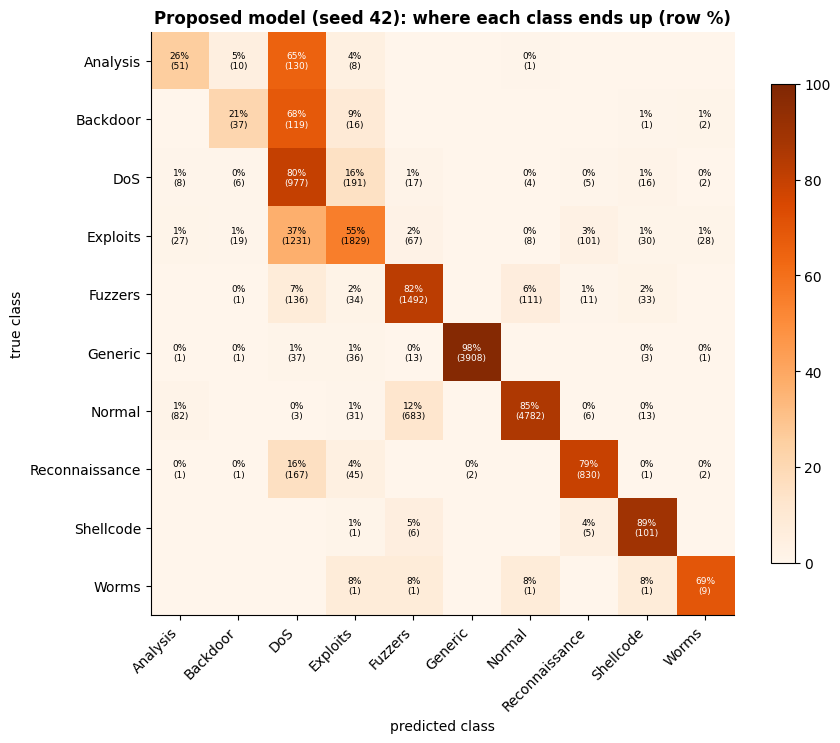

In [7]:
def class_f1(p):
    return f1_score(y_eval, p.argmax(1), average=None, labels=range(10), zero_division=0)


per_class = pd.DataFrame({'proposed (mean of seeds)': np.mean([class_f1(p) for p in proposed_proba.values()], axis=0),
                          best_lgbm_name: class_f1(lgbm[best_lgbm_name]),
                          'reference network (mean)': np.mean([class_f1(p) for p in reference.values()], axis=0),
                          'rows': np.bincount(y_eval, minlength=10)}, index=CLASSES)
save_table(per_class, '14_per_class', index=True)
display(per_class.round(3))

cm = confusion_matrix(y_eval, proposed_proba[42].argmax(1), labels=range(10))
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(cm_pct, cmap='Oranges', vmin=0, vmax=100)
ax.set_xticks(range(10), CLASSES, rotation=45, ha='right'); ax.set_yticks(range(10), CLASSES); ax.grid(False)
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, f'{cm_pct[i, j]:.0f}%\n({cm[i, j]})', ha='center', va='center', fontsize=6.5, color='white' if cm_pct[i, j] > 60 else 'black')
ax.set(xlabel='predicted class', ylabel='true class', title='Proposed model (seed 42): where each class ends up (row %)')
fig.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); save_figure(fig, '14_confusion'); plt.show()

**What we see:**

- The proposed model is **better than LightGBM on Analysis** (F1 0.28 vs 0.22) and close on DoS, Backdoor, Generic and Reconnaissance.
- LightGBM is far ahead on the **smallest classes**: Worms (0.73 vs 0.31) and Shellcode (0.75 vs 0.60). With 13 Worms and 113 Shellcode rows, these two
  classes alone explain much of the macro F1 gap, because macro F1 gives them the same weight as Normal.
- Compared with the reference network from Notebook 08, the biggest gains are DoS (0.06 → 0.48) and Worms (0.09 → 0.31).

## 6. Save

In [8]:
save_json({'config': PROPOSED, 'seeds': [42, 43, 44], 'chosen_by': 'stopping rows (train) for width and learning rate; Notebooks 10-13 decisions for parts'},
          MODELS / '14_proposed_config.json')
for seed, p in proposed_proba.items():
    out = data.targets['model_selection'][['row_position', 'id', 'attack_cat']].copy()
    out[[f'p_{c}' for c in CLASSES]] = p
    out.to_csv(DATA / f'14_proposed_seed{seed}_proba.csv', index=False)
write_leaderboard('14', [leaderboard_row('Proposed model', proposed_runs)])
assert sha256(TRAIN_CSV) == RAW_SHA256['train']
print('Saved the proposed configuration, probabilities and leaderboard row. Calibration rows and the test file were not used.')

Saved the proposed configuration, probabilities and leaderboard row. Calibration rows and the test file were not used.


## Summary

### What we learned

| Question | Answer |
|---|---|
| Proposed design | sqrt weighting + multi-scale Conv1D (3, 5, 7) + cross-attention fusion + TCN-BiLSTM, 64 channels, lr 0.001 (148k parameters) |
| Score | macro F1 **0.603 ± 0.011** on `model_selection` (3 seeds) |
| vs earlier networks | **Clearly better** than the MLP (+0.08) and the reference Conv1D + attention network (+0.07), for every seed |
| vs LightGBM (sqrt) | **Clearly worse** (0.603 vs 0.666) for every seed; the gap is mostly in Worms and Shellcode |
| Where it wins | Analysis (F1 0.28 vs 0.22) and slightly higher attack recall |

### What this means

The proposed architecture is a genuine improvement for neural networks on this data, but on single flow records a well-weighted tree ensemble remains
the stronger detector. Both statements will be reported.

### What comes next

**Notebook 15** removes each part of the proposed model one at a time (ablation), builds the final results table, tests a simple LightGBM + network
blend, and chooses the final detector.